In [8]:
import pandas as pd
import numpy as np
import scipy
if not hasattr(scipy, "interp"):
    scipy.interp = np.interp  # restore deprecated alias

from pycaret.classification import setup, compare_models, tune_model, pull


# Load your raw dataset
df_original = pd.read_csv("data.csv")

# ---- Feature groups (for convenience) ----
preop_basic = [
    "Age ", "BMI", "Tumor size", "Tumor size.1", "Tumor size.2", "Tumor volume",
    "Last BMI on file",
    "Pre-op visual impairment (y/n) - symptomatic complaint of visual loss",
    "Pre-op hydrocephalus (y/n)", "Pre-op intacranial pressure symptoms",
    "Pre-op headache", "Pre-op endocrine changes (y/n)",
    "Pre-op panhypopit (y/n) - define number of hormone axes that are non-functional",
    "Intraventricular extension"
]

intraop_basic = [
    "Surgical Approach",                 # raw categorical in df_original
    "Solid, cystic, mixed",              # raw categorical in df_original
    "Resection outcome (total, subtotal, partial)"
]

location_histology = [
    "Location (purely intrasellar, suprasellar/sellar, suprasellar/sellar with pseudoventricular extension, suprasellar/sellar with intraventricular extension, purely intraventricular)",
    "Tumor (Adamantinomatous, papillary)",
    "BRAF+"
]

# ---- Build 15 experiments (targets + feature sets) ----
experiments = [
    # Post-op complications
    {"target": "Recurrence after this operation",
     "features": preop_basic + ["Surgical Approach", "Resection outcome (total, subtotal, partial)"]}

    # Composite endpoints (you can create these columns beforehand if desired)
    # Example creation idea (run before the loop):
    # df_original["Any complication"] = (
    #     (df_original["CSF leak"]==1) | (df_original["Transient DI"]==1) |
    #     (df_original["Permanent DI"]==1) | (df_original["Other vascular complication (need to specify)"]==1) |
    #     (df_original["Hemorrhage or hemorrhagic stroke"]==1) | (df_original["Ischemic Stroke"]==1) |
    #     (df_original["Other intracranial infection"]==1) | (df_original["Non-intracranial infection"]==1) |
    #     (df_original["Meningitis"]==1)
    # ).astype(int)

    # If you already created it, uncomment the experiment below:
    # {"target": "Any complication",
    #  "features": preop_basic + intraop_basic + location_histology},

    # Visual outcome (binary version you can precompute; multi-class needs classification setup too)
    # df_original["VisualImproved"] = (df_original[
    #   "Post-op visual improvement/stable/worse (subjective); should add something specific about visual fields if any patients have; add about visual acuity"
    # ].astype(str).str.lower().str.contains("improv")).astype(int)

    # {"target": "VisualImproved",
    #  "features": preop_basic + ["Surgical Approach"] + location_histology},

    # Two more variations to reach 15 now (without needing new columns):

]

# ---- Utility: safe compare + tune ----
def run_experiment(df, target, features, metric="AUC"):
    # Keep only columns that exist (avoid KeyError if some columns are missing)
    cols = [c for c in features + [target] if c in df.columns]
    if target not in cols:
        print(f"  [skip] Target column '{target}' not found.")
        return None, None

    # Drop rows where target is missing
    data = df[cols].copy()
    data = data[~data[target].isna()]
    if data[target].nunique() < 2:
        print(f"  [skip] Target '{target}' has <2 classes after dropping NaNs.")
        return None, None

    # PyCaret setup
    clf_setup = setup(
        data=data,
        target=target,
        session_id=42,
        fold=3,                      # safer with rare events
        fold_strategy="stratifiedkfold",
        fix_imbalance=True,          # handle class imbalance
        use_gpu=False,
        verbose=False
    )

    # Compare and enforce single estimator
    best_model = compare_models(sort=metric, n_select=1)
    # Guard: sometimes returns list
    if isinstance(best_model, list):
        best_model = best_model[0]

    if not hasattr(best_model, "fit"):
        print("  [skip] No valid estimator returned by compare_models.")
        return None, None

    # Tune
    try:
        tuned = tune_model(best_model, optimize=metric)
    except Exception as e:
        print(f"  [warn] tune_model failed for '{target}': {e}")
        tuned = best_model

    leaderboard = pull()
    return tuned, leaderboard

# ---- Run all experiments ----
all_leaderboards = {}
for exp in experiments:
    print(f"\n=== Running target: {exp['target']} ===")
    try:
        tuned, leaderboard = run_experiment(df_original, exp["target"], exp["features"], metric="AUC")
        if leaderboard is not None:
            all_leaderboards[exp["target"]] = leaderboard.copy()
            # Show the top few rows for quick inspection
            print(leaderboard.head())
    except Exception as e:
        print(f"  [error] {exp['target']}: {e}")




=== Running target: Recurrence after this operation ===


,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,TT (Sec)
nb,Naive Bayes,0.7070,0.7694,0.7500,0.5000,0.5926,0.3775,0.4114,0.0467
qda,Quadratic Discriminant Analysis,0.7070,0.7444,0.0000,0.0000,0.0000,0.0000,0.0000,0.0500
ada,Ada Boost Classifier,0.7289,0.7389,0.5000,0.5333,0.5079,0.3246,0.3298,0.0867
lr,Logistic Regression,0.6832,0.7222,0.5833,0.3095,0.4040,0.2491,0.2880,0.0500
svm,SVM - Linear Kernel,0.6593,0.6815,0.4167,0.2917,0.3333,0.1641,0.1761,0.0467
et,Extra Trees Classifier,0.7051,0.6713,0.3333,0.6111,0.3952,0.2175,0.2563,0.1333
rf,Random Forest Classifier,0.7070,0.6676,0.3333,0.3333,0.3333,0.2000,0.2000,0.1367
ridge,Ridge Classifier,0.6081,0.6602,0.5833,0.3889,0.4667,0.1757,0.1845,0.0467
gbc,Gradient Boosting Classifier,0.6392,0.6565,0.5000,0.5397,0.4768,0.2225,0.2436,0.0867
xgboost,Extreme Gradient Boosting,0.7308,0.6509,0.4167,0.5556,0.4683,0.2979,0.3060,0.0767


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.6429,0.6500,0.5000,0.4000,0.4444,0.1860,0.1886
1,0.7857,0.8125,0.7500,0.6000,0.6667,0.5116,0.5185
2,0.7692,0.8333,1.0000,0.5714,0.7273,0.5517,0.6172
Mean,0.7326,0.7653,0.7500,0.5238,0.6128,0.4165,0.4414
Std,0.0638,0.0820,0.2041,0.0883,0.1216,0.1638,0.1833


Fitting 3 folds for each of 10 candidates, totalling 30 fits
Original model was better than the tuned model, hence it will be returned. NOTE: The display metrics are for the tuned model (not the original one).
      Accuracy     AUC  Recall   Prec.      F1   Kappa     MCC
Fold                                                          
0       0.6429  0.6500  0.5000  0.4000  0.4444  0.1860  0.1886
1       0.7857  0.8125  0.7500  0.6000  0.6667  0.5116  0.5185
2       0.7692  0.8333  1.0000  0.5714  0.7273  0.5517  0.6172
Mean    0.7326  0.7653  0.7500  0.5238  0.6128  0.4165  0.4414
Std     0.0638  0.0820  0.2041  0.0883  0.1216  0.1638  0.1833


In [9]:
import pandas as pd
from pycaret.classification import setup, create_model, tune_model, finalize_model, save_model, predict_model, pull

# 1) Load raw data
df_original = pd.read_csv("data.csv")

# 2) Define features for Permanent DI (pre-op + intra-op you chose)
features_permdi = [
    "Age ", "BMI", "Tumor size", "Tumor size.1", "Tumor size.2", "Tumor volume",
    "Last BMI on file",
    "Pre-op visual impairment (y/n) - symptomatic complaint of visual loss",
    "Pre-op hydrocephalus (y/n)", "Pre-op intacranial pressure symptoms",
    "Pre-op headache", "Pre-op endocrine changes (y/n)",
    "Pre-op panhypopit (y/n) - define number of hormone axes that are non-functional",
    "Intraventricular extension",
    "Surgical Approach", "Resection outcome (total, subtotal, partial)"
]
target = "Recurrence after this operation"

# 3) Keep only rows with target present
cols = [c for c in features_permdi + [target] if c in df_original.columns]
data = df_original[cols].dropna(subset=[target]).copy()

# 4) Pick a safe number of folds (avoid empty-class folds)
vc = data[target].value_counts()
minority = int(vc.min())
folds = max(2, min(3, minority))  # 2–3 folds depending on minority size

# 5) Setup (PyCaret will encode categoricals & impute internally)
_ = setup(
    data=data,
    target=target,
    session_id=42,
    fold=folds,
    fold_strategy="stratifiedkfold",
    fix_imbalance=True,    # helps with rare outcomes
    use_gpu=False,
    verbose=False
)

# 6) Train Ridge, then tune it (optimize F1 for class imbalance)
nb = create_model("nb")
nb_tuned = tune_model(nb, optimize="F1")

# (optional) Inspect CV leaderboard for tuned ridge
lb = pull()
print(lb.head())

# 7) Finalize on the full dataset (locks preprocessing + tuned params)
nb_final = finalize_model(nb_tuned)

# 8) Save the whole pipeline (preprocessing + model)
save_model(nb_final, "permi_nb_v1")

# 9) (optional) Get CV/holdout predictions for sanity check
preds = predict_model(nb_final)
print(preds.head())


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.6429,0.6500,0.5000,0.4000,0.4444,0.1860,0.1886
1,0.7857,0.8250,0.7500,0.6000,0.6667,0.5116,0.5185
2,0.6923,0.8333,1.0000,0.5000,0.6667,0.4348,0.5270
Mean,0.7070,0.7694,0.7500,0.5000,0.5926,0.3775,0.4114
Std,0.0592,0.0845,0.2041,0.0816,0.1048,0.1390,0.1576


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.6429,0.6500,0.5000,0.4000,0.4444,0.1860,0.1886
1,0.7857,0.8125,0.7500,0.6000,0.6667,0.5116,0.5185
2,0.7692,0.8333,1.0000,0.5714,0.7273,0.5517,0.6172
Mean,0.7326,0.7653,0.7500,0.5238,0.6128,0.4165,0.4414
Std,0.0638,0.0820,0.2041,0.0883,0.1216,0.1638,0.1833


Fitting 3 folds for each of 10 candidates, totalling 30 fits
      Accuracy     AUC  Recall   Prec.      F1   Kappa     MCC
Fold                                                          
0       0.6429  0.6500  0.5000  0.4000  0.4444  0.1860  0.1886
1       0.7857  0.8125  0.7500  0.6000  0.6667  0.5116  0.5185
2       0.7692  0.8333  1.0000  0.5714  0.7273  0.5517  0.6172
Mean    0.7326  0.7653  0.7500  0.5238  0.6128  0.4165  0.4414
Std     0.0638  0.0820  0.2041  0.0883  0.1216  0.1638  0.1833
Transformation Pipeline and Model Successfully Saved


,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
0,Naive Bayes,0.5000,0.7692,0.8000,0.3333,0.4706,0.1290,0.1754


    Age     BMI  Tumor size  Tumor size.1  Tumor size.2  Tumor volume  \
37    49    NaN         1.9           1.4           1.0      1.392772   
53    52  26.99         3.6           3.8           3.8     27.218737   
13    64  24.01         2.7           1.5           2.1      4.453204   
34    45  29.34         2.8           2.5           1.6      5.864301   
4     14  20.60         NaN           NaN           NaN           NaN   

    Last BMI on file  \
37         37.549999   
53         33.720001   
13         23.770000   
34         29.900000   
4          23.100000   

    Pre-op visual impairment (y/n) - symptomatic complaint of visual loss  \
37                                                1.0                       
53                                                1.0                       
13                                                1.0                       
34                                                1.0                       
4                              

In [10]:
from sklearn.metrics import classification_report
from pycaret.classification import get_config

X_train = get_config("X_train")
y_train = get_config("y_train")
preds = nb_final.predict(X_train)

print(classification_report(y_train, preds, digits=3))


              precision    recall  f1-score   support

           0      0.941     0.552     0.696        29
           1      0.458     0.917     0.611        12

    accuracy                          0.659        41
   macro avg      0.700     0.734     0.653        41
weighted avg      0.800     0.659     0.671        41



In [15]:
import pandas as pd
from pycaret.classification import get_config
from sklearn.inspection import permutation_importance

# Get the raw training data used inside the current PyCaret session
X_train = get_config("X_train")
y_train = get_config("y_train")

# nb_final is your finalized PyCaret pipeline (preprocessing + NB)
r = permutation_importance(
    nb_final, X_train, y_train,
    n_repeats=30, random_state=42, scoring="f1"  # use the metric you care about
)

imp = pd.Series(r.importances_mean, index=X_train.columns).sort_values(ascending=False)
print(imp.head(20))          # top 20 features


Pre-op panhypopit (y/n) - define number of hormone axes that are non-functional    0.072763
Pre-op visual impairment (y/n) - symptomatic complaint of visual loss              0.061105
Age                                                                                0.027461
BMI                                                                                0.007282
Pre-op hydrocephalus (y/n)                                                         0.000000
Pre-op intacranial pressure symptoms                                               0.000000
Pre-op endocrine changes (y/n)                                                     0.000000
Surgical Approach                                                                  0.000000
Last BMI on file                                                                  -0.000090
Tumor volume                                                                      -0.000701
Tumor size.1                                                                    

,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.6429,0.6500,0.5000,0.4000,0.4444,0.1860,0.1886
1,0.7857,0.8250,0.7500,0.6000,0.6667,0.5116,0.5185
2,0.6923,0.8333,1.0000,0.5000,0.6667,0.4348,0.5270
Mean,0.7070,0.7694,0.7500,0.5000,0.5926,0.3775,0.4114
Std,0.0592,0.0845,0.2041,0.0816,0.1048,0.1390,0.1576


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.7143,0.5000,0.5000,0.5000,0.5000,0.3000,0.3000
1,0.7857,0.8750,0.2500,1.0000,0.4000,0.3226,0.4385
2,0.6154,0.6389,0.2500,0.3333,0.2857,0.0299,0.0304
Mean,0.7051,0.6713,0.3333,0.6111,0.3952,0.2175,0.2563
Std,0.0698,0.1548,0.1179,0.2833,0.0875,0.1330,0.1694


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.6429,0.8500,1.0000,0.4444,0.6154,0.3636,0.4714
1,0.6429,0.8250,0.7500,0.4286,0.5455,0.2857,0.3162
2,0.6154,0.7083,0.5000,0.4000,0.4444,0.1558,0.1581
Mean,0.6337,0.7944,0.7500,0.4243,0.5351,0.2684,0.3152
Std,0.0130,0.0617,0.2041,0.0184,0.0702,0.0857,0.1279


Fitting 3 folds for each of 10 candidates, totalling 30 fits


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.7143,0.6750,0.5000,0.5000,0.5000,0.3000,0.3000
1,0.8571,0.8250,0.7500,0.7500,0.7500,0.6500,0.6500
2,0.8462,0.8611,1.0000,0.6667,0.8000,0.6829,0.7201
Mean,0.8059,0.7870,0.7500,0.6389,0.6833,0.5443,0.5567
Std,0.0649,0.0806,0.2041,0.1039,0.1312,0.1733,0.1838


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.7143,0.7750,0.5000,0.5000,0.5000,0.3000,0.3000
1,0.8571,0.8750,0.7500,0.7500,0.7500,0.6500,0.6500
2,0.6923,0.8611,0.7500,0.5000,0.6000,0.3659,0.3858
Mean,0.7546,0.8370,0.6667,0.5833,0.6167,0.4386,0.4453
Std,0.0731,0.0442,0.1179,0.1179,0.1027,0.1519,0.1490


      Accuracy     AUC  Recall   Prec.      F1   Kappa     MCC
Fold                                                          
0       0.7143  0.7750  0.5000  0.5000  0.5000  0.3000  0.3000
1       0.8571  0.8750  0.7500  0.7500  0.7500  0.6500  0.6500
2       0.6923  0.8611  0.7500  0.5000  0.6000  0.3659  0.3858
Mean    0.7546  0.8370  0.6667  0.5833  0.6167  0.4386  0.4453
Std     0.0731  0.0442  0.1179  0.1179  0.1027  0.1519  0.1490


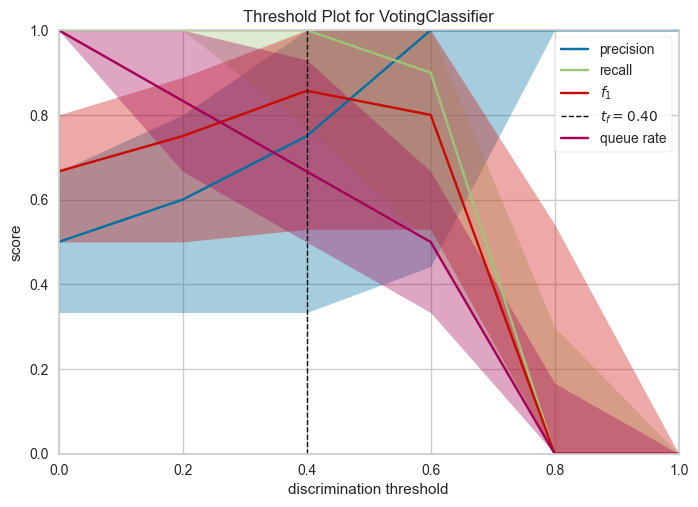

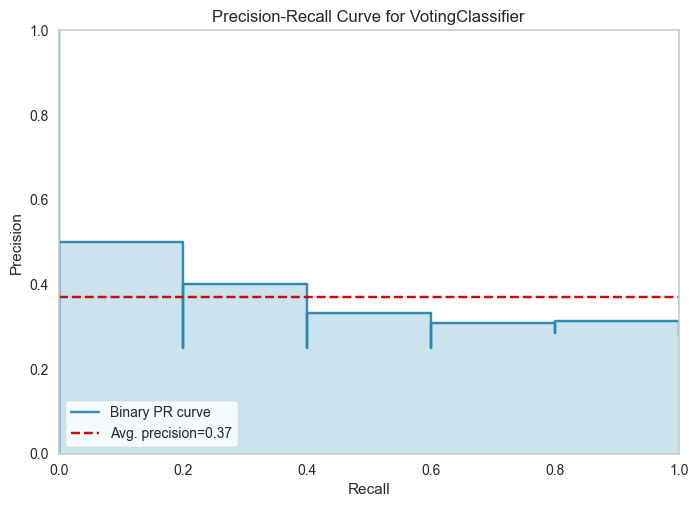

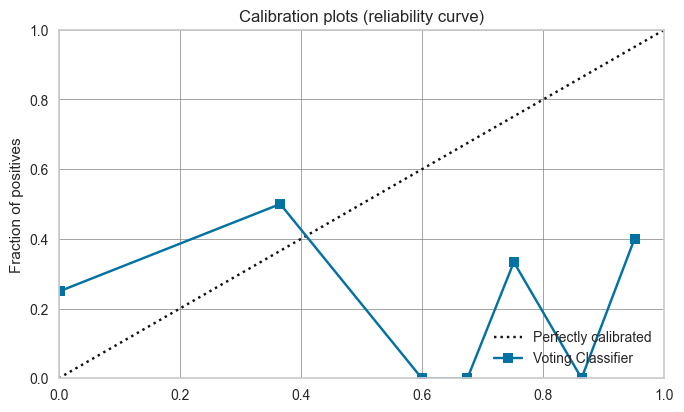

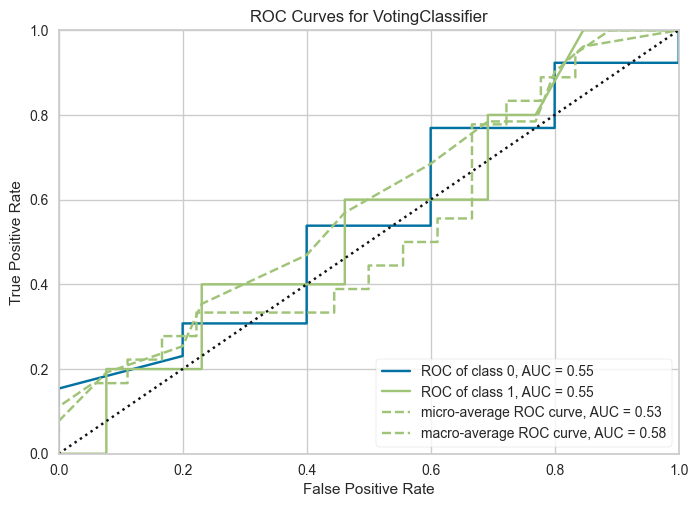

Transformation Pipeline and Model Successfully Saved


(Pipeline(memory=Memory(location=None),
          steps=[('numerical_imputer',
                  TransformerWrapper(exclude=None,
                                     include=['Age ', 'BMI', 'Tumor size',
                                              'Tumor size.1', 'Tumor size.2',
                                              'Tumor volume', 'Last BMI on file',
                                              'Pre-op visual impairment (y/n) - '
                                              'symptomatic complaint of visual '
                                              'loss',
                                              'Pre-op hydrocephalus (y/n)',
                                              'Pre-op intacranial pressure '
                                              'symptoms',
                                              'Pre-op headache',
                                              'Pre-op endoc...
                                                                     max_featur

In [16]:
import pandas as pd
from pycaret.classification import (
    setup, create_model, tune_model, calibrate_model,
    blend_models, compare_models, finalize_model, save_model, pull
)

# --- Build the modeling table exactly as before ---
df = pd.read_csv("data.csv")
features_permdi = [
    "Age ", "BMI", "Tumor size", "Tumor size.1", "Tumor size.2", "Tumor volume",
    "Last BMI on file",
    "Pre-op visual impairment (y/n) - symptomatic complaint of visual loss",
    "Pre-op hydrocephalus (y/n)", "Pre-op intacranial pressure symptoms",
    "Pre-op headache", "Pre-op endocrine changes (y/n)",
    "Pre-op panhypopit (y/n) - define number of hormone axes that are non-functional",
    "Intraventricular extension",
    "Surgical Approach", "Resection outcome (total, subtotal, partial)"
]
target = "Recurrence after this operation"

data = df[features_permdi + [target]].dropna(subset=[target]).copy()
folds = max(2, min(3, int(data[target].value_counts().min())))

_ = setup(
    data=data,
    target=target,
    session_id=42,
    fold=folds,
    fold_strategy="stratifiedkfold",
    fix_imbalance=True,
    verbose=False
)

# Base learners
nb = create_model("nb")                     # strong precision
et   = create_model("et")                  # strong recall
# Optional tuning (often helps catboost a bit)
et_t = tune_model(et, optimize="F1")

# Calibrate ridge (gives reliable proba for blending / ROC)
nb_cal = calibrate_model(nb, method="isotonic")  # or "sigmoid"

# Blend (soft vote on calibrated probabilities)
blend = blend_models(
    estimator_list=[nb_cal, et_t],
    method="soft",          # uses probabilities
    optimize="AUC"          # or "F1" if you care more about positives
)

# See CV metrics of the blend
print(pull().head())

# Threshold tuning (pick operating point)
from pycaret.classification import plot_model
plot_model(blend, plot="threshold")       # interactively pick threshold
plot_model(blend, plot="pr")              # PR curve is informative for rare events
plot_model(blend, plot="calibration")     # check probability calibration
plot_model(blend, plot="auc")

# Finalize & save
blend_final = finalize_model(blend)
save_model(blend_final, "permdi_blend_nb_et_v1")



In [32]:
print("\n=== NB (base) ===")
nb = create_model("nb")
print(pull())

print("\n=== ET (base) ===")
et = create_model("et")
print(pull())

print("\n=== et (tuned) ===")
et_t = tune_model(et, optimize="F1")
print(pull())

print("\n=== NB Calibrated (isotonic) ===")
nb_cal = calibrate_model(nb, method="isotonic")
print(pull())

print("\n=== Blend (RidgeCal + CatBoost) ===")
blend = blend_models([nb_cal, et_t], method="soft", optimize="AUC")
print(pull())



=== NB (base) ===


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.6429,0.6500,0.5000,0.4000,0.4444,0.1860,0.1886
1,0.7857,0.8250,0.7500,0.6000,0.6667,0.5116,0.5185
2,0.6923,0.8333,1.0000,0.5000,0.6667,0.4348,0.5270
Mean,0.7070,0.7694,0.7500,0.5000,0.5926,0.3775,0.4114
Std,0.0592,0.0845,0.2041,0.0816,0.1048,0.1390,0.1576


      Accuracy     AUC  Recall   Prec.      F1   Kappa     MCC
Fold                                                          
0       0.6429  0.6500  0.5000  0.4000  0.4444  0.1860  0.1886
1       0.7857  0.8250  0.7500  0.6000  0.6667  0.5116  0.5185
2       0.6923  0.8333  1.0000  0.5000  0.6667  0.4348  0.5270
Mean    0.7070  0.7694  0.7500  0.5000  0.5926  0.3775  0.4114
Std     0.0592  0.0845  0.2041  0.0816  0.1048  0.1390  0.1576

=== ET (base) ===


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.7143,0.5000,0.5000,0.5000,0.5000,0.3000,0.3000
1,0.7857,0.8750,0.2500,1.0000,0.4000,0.3226,0.4385
2,0.6154,0.6389,0.2500,0.3333,0.2857,0.0299,0.0304
Mean,0.7051,0.6713,0.3333,0.6111,0.3952,0.2175,0.2563
Std,0.0698,0.1548,0.1179,0.2833,0.0875,0.1330,0.1694


      Accuracy     AUC  Recall   Prec.      F1   Kappa     MCC
Fold                                                          
0       0.7143  0.5000  0.5000  0.5000  0.5000  0.3000  0.3000
1       0.7857  0.8750  0.2500  1.0000  0.4000  0.3226  0.4385
2       0.6154  0.6389  0.2500  0.3333  0.2857  0.0299  0.0304
Mean    0.7051  0.6713  0.3333  0.6111  0.3952  0.2175  0.2563
Std     0.0698  0.1548  0.1179  0.2833  0.0875  0.1330  0.1694

=== et (tuned) ===


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.6429,0.8500,1.0000,0.4444,0.6154,0.3636,0.4714
1,0.6429,0.8250,0.7500,0.4286,0.5455,0.2857,0.3162
2,0.6154,0.7083,0.5000,0.4000,0.4444,0.1558,0.1581
Mean,0.6337,0.7944,0.7500,0.4243,0.5351,0.2684,0.3152
Std,0.0130,0.0617,0.2041,0.0184,0.0702,0.0857,0.1279


Fitting 3 folds for each of 10 candidates, totalling 30 fits
      Accuracy     AUC  Recall   Prec.      F1   Kappa     MCC
Fold                                                          
0       0.6429  0.8500  1.0000  0.4444  0.6154  0.3636  0.4714
1       0.6429  0.8250  0.7500  0.4286  0.5455  0.2857  0.3162
2       0.6154  0.7083  0.5000  0.4000  0.4444  0.1558  0.1581
Mean    0.6337  0.7944  0.7500  0.4243  0.5351  0.2684  0.3152
Std     0.0130  0.0617  0.2041  0.0184  0.0702  0.0857  0.1279

=== NB Calibrated (isotonic) ===


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.7143,0.6750,0.5000,0.5000,0.5000,0.3000,0.3000
1,0.8571,0.8250,0.7500,0.7500,0.7500,0.6500,0.6500
2,0.8462,0.8611,1.0000,0.6667,0.8000,0.6829,0.7201
Mean,0.8059,0.7870,0.7500,0.6389,0.6833,0.5443,0.5567
Std,0.0649,0.0806,0.2041,0.1039,0.1312,0.1733,0.1838


      Accuracy     AUC  Recall   Prec.      F1   Kappa     MCC
Fold                                                          
0       0.7143  0.6750  0.5000  0.5000  0.5000  0.3000  0.3000
1       0.8571  0.8250  0.7500  0.7500  0.7500  0.6500  0.6500
2       0.8462  0.8611  1.0000  0.6667  0.8000  0.6829  0.7201
Mean    0.8059  0.7870  0.7500  0.6389  0.6833  0.5443  0.5567
Std     0.0649  0.0806  0.2041  0.1039  0.1312  0.1733  0.1838

=== Blend (RidgeCal + CatBoost) ===


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.7143,0.7750,0.5000,0.5000,0.5000,0.3000,0.3000
1,0.8571,0.8750,0.7500,0.7500,0.7500,0.6500,0.6500
2,0.6923,0.8611,0.7500,0.5000,0.6000,0.3659,0.3858
Mean,0.7546,0.8370,0.6667,0.5833,0.6167,0.4386,0.4453
Std,0.0731,0.0442,0.1179,0.1179,0.1027,0.1519,0.1490


      Accuracy     AUC  Recall   Prec.      F1   Kappa     MCC
Fold                                                          
0       0.7143  0.7750  0.5000  0.5000  0.5000  0.3000  0.3000
1       0.8571  0.8750  0.7500  0.7500  0.7500  0.6500  0.6500
2       0.6923  0.8611  0.7500  0.5000  0.6000  0.3659  0.3858
Mean    0.7546  0.8370  0.6667  0.5833  0.6167  0.4386  0.4453
Std     0.0731  0.0442  0.1179  0.1179  0.1027  0.1519  0.1490


In [35]:
from pycaret.classification import stack_models, create_model

# (continue from the same setup; reuse ridge_cal and cat_t)
rf   = create_model("rf")
xgb  = create_model("xgboost")

stack = stack_models(
    estimator_list=[nb_cal, et_t, rf, xgb],
    meta_model=create_model("lr"),   # meta learner
    optimize="AUC"                   # or "F1"
)




,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.7143,0.4750,0.5000,0.5000,0.5000,0.3000,0.3000
1,0.7143,0.7500,0.5000,0.5000,0.5000,0.3000,0.3000
2,0.6923,0.7778,0.0000,0.0000,0.0000,0.0000,0.0000
Mean,0.7070,0.6676,0.3333,0.3333,0.3333,0.2000,0.2000
Std,0.0104,0.1367,0.2357,0.2357,0.2357,0.1414,0.1414


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.7857,0.8250,0.5000,0.6667,0.5714,0.4324,0.4404
1,0.7143,0.6000,0.5000,0.5000,0.5000,0.3000,0.3000
2,0.6923,0.5278,0.2500,0.5000,0.3333,0.1613,0.1777
Mean,0.7308,0.6509,0.4167,0.5556,0.4683,0.2979,0.3060
Std,0.0399,0.1266,0.1179,0.0786,0.0998,0.1107,0.1073


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.7143,0.7750,1.0000,0.5000,0.6667,0.4615,0.5477
1,0.6429,0.7250,0.7500,0.4286,0.5455,0.2857,0.3162
2,0.6923,0.6667,0.0000,0.0000,0.0000,0.0000,0.0000
Mean,0.6832,0.7222,0.5833,0.3095,0.4040,0.2491,0.2880
Std,0.0299,0.0443,0.4249,0.2208,0.2900,0.1902,0.2245


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.7143,0.5250,0.5000,0.5000,0.5000,0.3000,0.3000
1,0.7857,0.7250,0.5000,0.6667,0.5714,0.4324,0.4404
2,0.7692,0.8056,0.2500,1.0000,0.4000,0.3158,0.4330
Mean,0.7564,0.6852,0.4167,0.7222,0.4905,0.3494,0.3911
Std,0.0305,0.1179,0.1179,0.2079,0.0703,0.0591,0.0645


In [26]:
print(pull().head())
stack_final = finalize_model(stack)

      Accuracy     AUC  Recall   Prec.      F1   Kappa     MCC
Fold                                                          
0       0.7143  0.7750  0.5000  0.5000  0.5000  0.3000  0.3000
1       0.8571  0.8750  0.7500  0.7500  0.7500  0.6500  0.6500
2       0.8462  0.8889  0.7500  0.7500  0.7500  0.6389  0.6389
Mean    0.8059  0.8463  0.6667  0.6667  0.6667  0.5296  0.5296
Std     0.0649  0.0507  0.1179  0.1179  0.1179  0.1624  0.1624
